# Using Google Colab

Read through the **Getting started** paragraph in the [official documentation](https://colab.research.google.com/). You may also want to take a look into the **More resources** section.

To add a new code block or text block, use the buttons in the menus above or hover your mouse between two blocks, where more buttons should appear.

To execute all code blocks within this document, select `Runtime -> Run all`. When you submit your solution, this should run without throwing an error.

Sometimes, previously defined variables cause trouble in later executions. If this is the case, you can select `Runtime -> Restart runtime` to restart the runtime and erase all previous definitions.

# Guidelines for Solving the Assignments

In these assignments, you are expected to implement the algorithms yourself rather than relying on Python’s built-in functions that already solve essential parts of the task, such as `index`, `min`, `max`, or `sort`. However, it is of course fine to use general-purpose functions like `len` or `range`.

You may discuss the assignments in general terms with other groups to clarify ideas, but every group must produce their own solutions independently. Copying solutions (or parts thereof) from other groups or from external sources is strictly prohibited—this includes material generated by AI text generators such as ChatGPT or similar tools.

# Work Distribution

***Your answer here. (MANDATORY)***

# Initialisation

This section contains code that is later used to test, measure and plot your implementations. You need to run it once to initialise it.

⇩ Click here to initialise the code.

In [ ]:
# tests

import random

def shuffle(list):
  random.shuffle(list)
  return list

tests = [(name, unsorted, sorted(unsorted)) for (name, unsorted) in [
    ("empty list", []),
    ("one element", [42]),
    ("digits ascending", list(range(10))),
    ("digits descending", list(reversed(range(10)))),
    ("digits shuffled", shuffle(list(range(10)))),
    ("all entries the same", [42 for _ in range(10)]),
    ("some duplicates", shuffle(list(range(10)) + list(range(5)))),
    ("negative numbers", shuffle([x - 10 for x in list(range(20))])),
    ("float numbers", shuffle([x * 3.14 for x in list(range(20))])),
    ("mixed numbers", shuffle([x * 3.14 for x in list(range(10))] + list(range(10)))),
    *[("random numbers " + str(idx) + " (small)", [random.randrange(1000) for _ in range(20)]) for idx in range(0, 5)],
    *[("random numbers " + str(idx) + " (medium)", [random.randrange(10000) for _ in range(200)]) for idx in range(5, 10)],
    *[("random numbers " + str(idx) + " (large)", [random.randrange(100000) for _ in range(2000)]) for idx in range(10, 15)],
]]

def run_tests(fun):
  print("executing all tests on %s..." % (fun.__name__))
  ok = 0
  err = 0
  for name, input, expected in tests:
    copy = input.copy()
    try:
      fun(copy)
    except Exception as e:
      print("Test '%s' raised an exception!\n  input:     %s\n  expected:  %s\n  exception: %s" % (name, input, expected, e))
      raise e
    else:
      if copy == expected:
        print("Test '%s' passed!" % (name))
        ok += 1
      else:
        print("Test '%s' failed!\n  input:     %s\n  output:    %s\n  expected:  %s" % (name, input, copy, expected))
        err +=1
  print("%s (summary): %d/%d OK, %d/%d ERROR" % (fun.__name__, ok, len(tests), err, len(tests)))

# runtime parameters
num_samples = 20
sizes = [2000 * i for i in range(1, 10)]

# runtime measurement
import time
runtimeDict = {}
def measure_runtime(funs):
  inputs = [[[random.random() for _ in range(size)] for _ in range(num_samples)] for size in sizes]

  for fun in funs:
    runtimes = []
    for batch in inputs:
      batch_rt = []
      for input in batch:
        copy = input.copy()
        start_time = time.time()
        fun(copy)
        end_time = time.time()
        batch_rt.append(end_time - start_time)
      runtimes.append(min(batch_rt))
    runtimeDict[fun.__name__] = runtimes

# runtime plot
import matplotlib.pyplot as plt
def plot_runtime(funs, funs_checkered=None):
  for fun in funs:
    plt.plot(sizes, runtimeDict[fun.__name__], label=fun.__name__)
  if funs_checkered:
    plt.gca().set_prop_cycle(None)
    for fun in funs_checkered:
      plt.plot(sizes, runtimeDict[fun.__name__], '--', label=fun.__name__)

  plt.xlabel('List Length')
  plt.ylabel('Runtime (seconds)')
  plt.title('Runtime vs List Length')

  plt.legend()
  plt.show()

# Sorting Algorithms

In this exercise, you are going to implement the *Merge Sort*, *Quick Sort* and *Heap Sort* algorithms.

- Each of your sorting functions should accept an unsorted list of numbers and sort it. Of course, you are allowed to add as many helper functions as needed.
- Note that arrays (or lists) in the textbook are indexed from 1, whereas in Python (and most other programming languages) they are indexed from 0.
- Your implementation should have a good performance with respect to the asymptotic complexity found in the literature.

At the bottom of each code block, there is a function call to test your algorithm implementation. Run it to check if your implementation is correct.

Below the algorithms in this document, there is a code block that reports runtime statistics. Furthermore, at the end of the document, there are a couple of questions you should answer.

### 1. Merge Sort (2 points)

Implement Merge Sort as seen in the lecture.

Hint: Start by implementing `merge` and then use it to implement `mergesort`.

In [ ]:

def merge(A,p,q,r):
  # our p is our left
  # our q is our middle point
  # our r is our right
  # I would prefer (l,m,r)

  nL = q-p+1
  nR = r-q

  # we distribute the new arrays
  #(just to allocate space where the numbers will go, with 0s)
  L = [0]* nL
  R = [0]* nR

  # we put the numbers in the respective list
  for i in range(nL):
    L[i]= A[p+i]

  for j in range(nR):
    R[j] = A[q+j+1]

  # this is our index for the position of each element
  i = 0
  j = 0
  k = p

  # translation of the pseudocode we have
  while i < nL and j < nR:
    if L[i] <= R[j]:
      A[k] = L[i]
      i += 1
    else:
      A[k] = R[j]
      j += 1
    k += 1

  while i < nL:
    A[k] = L[i]
    i += 1
    k += 1

  while j < nR:
    A[k] = R[j]
    j += 1
    k += 1

# we need to arrange this as such so its faithful to the book / class
def mergesort(A,p=None,r=None):
  # The inmediate return if len(A) = 0/1 (our base case)/(like in leetcode)
  # and the activation of the parameters we need to solve this this way
  if p is None:
      p = 0
  if r is None:
      r = len(A) - 1
  if p >= r:
    return

  # this is our middle point
  q = ((p+r)//2)

  # operations:
  # Left side sorting recursively
  mergesort(A,p,q)
  # right side sorting
  mergesort(A,q+1,r)
  # putting them back together
  merge(A,p,q,r)

run_tests(mergesort)

executing all tests on mergesort...
Test 'empty list' passed!
Test 'one element' passed!
Test 'digits ascending' passed!
Test 'digits descending' passed!
Test 'digits shuffled' passed!
Test 'all entries the same' passed!
Test 'some duplicates' passed!
Test 'negative numbers' passed!
Test 'float numbers' passed!
Test 'mixed numbers' passed!
Test 'random numbers 0 (small)' passed!
Test 'random numbers 1 (small)' passed!
Test 'random numbers 2 (small)' passed!
Test 'random numbers 3 (small)' passed!
Test 'random numbers 4 (small)' passed!
Test 'random numbers 5 (medium)' passed!
Test 'random numbers 6 (medium)' passed!
Test 'random numbers 7 (medium)' passed!
Test 'random numbers 8 (medium)' passed!
Test 'random numbers 9 (medium)' passed!
Test 'random numbers 10 (large)' passed!
Test 'random numbers 11 (large)' passed!
Test 'random numbers 12 (large)' passed!
Test 'random numbers 13 (large)' passed!
Test 'random numbers 14 (large)' passed!
mergesort (summary): 25/25 OK, 0/25 ERROR


### 2. Quick Sort (2 points)

Implement Quick Sort as seen in the lecture.

Hint: Start by implementing `partition` and then use it to implement `quicksort`.

In [ ]:
def partition(A, p, r):
  x = A[r]
  i = p - 1
  # Just to keep the consistency with the book:
  j = p

  # we go from our start point to the index of our pivot
  for j in range(p,r):
    # we here compare if its bigger or smaller to put them on the according list to sort
    if A[j] <= x:
      i += 1
      A[i],A[j] = A[j],A[i]
  # here we move  the pivot to the organized list
  A[i+1],A[r] = A[r], A[i+1]
  return i + 1

def quicksort(A, p = None, r = None):
  if p is None:
    p = 0
  if r is None:
    r = len(A)-1

  # we do this to have a recursive call
  if p < r:
    q = partition(A,p,r)
    # we go from the beginning to the one previous to our pivot
    quicksort(A,p,q-1) # sort the low side
    # we go from the pivot to the end to our list
    quicksort(A,q+1,r) # sort the high side



run_tests(quicksort)

executing all tests on quicksort...
Test 'empty list' passed!
Test 'one element' passed!
Test 'digits ascending' passed!
Test 'digits descending' passed!
Test 'digits shuffled' passed!
Test 'all entries the same' passed!
Test 'some duplicates' passed!
Test 'negative numbers' passed!
Test 'float numbers' passed!
Test 'mixed numbers' passed!
Test 'random numbers 0 (small)' passed!
Test 'random numbers 1 (small)' passed!
Test 'random numbers 2 (small)' passed!
Test 'random numbers 3 (small)' passed!
Test 'random numbers 4 (small)' passed!
Test 'random numbers 5 (medium)' passed!
Test 'random numbers 6 (medium)' passed!
Test 'random numbers 7 (medium)' passed!
Test 'random numbers 8 (medium)' passed!
Test 'random numbers 9 (medium)' passed!
Test 'random numbers 10 (large)' passed!
Test 'random numbers 11 (large)' passed!
Test 'random numbers 12 (large)' passed!
Test 'random numbers 13 (large)' passed!
Test 'random numbers 14 (large)' passed!
quicksort (summary): 25/25 OK, 0/25 ERROR


### 3. Heap Sort (3 points)

Implement Heap Sort as seen in the lecture.

Note that you do not have to define a new class for heaps (unless you
want to), instead you can just use a plain list to store the heap and
pass along an extra parameter `heap_size` to the functions that need it.

Hint: Start by implementing `max_heapify` and `build_max_heap`, and then use them to implement `heapsort`.

In [ ]:
def max_heapify(A,i, heap_size):

  # i had to search how to do this since its not a root tree that we could do root.left / root.right
  # so i based myself on this: https://www.reddit.com/r/computerscience/comments/tbk6am/is_there_a_general_formula_for_finding_the/
  # but since python starts at 0 and the pseudocode at 1, we need to adapt it (maybe it works without this change)

  l = 2 * i +1
  r = 2 * i +2


  # again we need to adapt to the different indexing
  if l <= heap_size-1 and A[l] > A[i]:
    largest = l
  else:
    largest = i

  if r <= heap_size-1 and A[r] > A[largest]:
    largest = r

  if largest != i:
    A[i],A[largest] = A[largest],A[i]
    max_heapify(A,largest, heap_size)

def build_max_heap(A,n,heap_size):
  # n = len(A) this is literally the same as the heap size we use

  # in decreasing order
  # again we need to adapt to the different indexing (literally always -1)
  # we go through the parents , we arrange for the parent to be at the "root"
                          #start #stop #steps
  for i in range((heap_size//2)-1,-1,-1):
    max_heapify(A,i,heap_size)

def heapsort(A,n = None):
  # we dont modify the size of the list , instead we do a variable to store the changes
  heap_size = len(A)
  if n is None:
    n = 0
  build_max_heap(A,n,heap_size)

   # in decreasing order
   # again we need to adapt to the different indexing (here we use 0, as we dont care about the bigger one)
  for i in range(heap_size-1 ,0,-1):
    # we need to adapt to python indexing so 1 (first) is our 0
    A[0],A[i] = A[i],A[0]
    heap_size -= 1
    max_heapify(A,0,heap_size)

run_tests(heapsort)

executing all tests on heapsort...
Test 'empty list' passed!
Test 'one element' passed!
Test 'digits ascending' passed!
Test 'digits descending' passed!
Test 'digits shuffled' passed!
Test 'all entries the same' passed!
Test 'some duplicates' passed!
Test 'negative numbers' passed!
Test 'float numbers' passed!
Test 'mixed numbers' passed!
Test 'random numbers 0 (small)' passed!
Test 'random numbers 1 (small)' passed!
Test 'random numbers 2 (small)' passed!
Test 'random numbers 3 (small)' passed!
Test 'random numbers 4 (small)' passed!
Test 'random numbers 5 (medium)' passed!
Test 'random numbers 6 (medium)' passed!
Test 'random numbers 7 (medium)' passed!
Test 'random numbers 8 (medium)' passed!
Test 'random numbers 9 (medium)' passed!
Test 'random numbers 10 (large)' passed!
Test 'random numbers 11 (large)' passed!
Test 'random numbers 12 (large)' passed!
Test 'random numbers 13 (large)' passed!
Test 'random numbers 14 (large)' passed!
heapsort (summary): 25/25 OK, 0/25 ERROR


### 4. Runtime Comparisons (2 points)

The following code will measure the runtime of your algorithm implementations.

Compare the reported runtimes. What do you observe? How do you explain your observations?

How do the runtimes compare to those from the first assignment sheet (Insertion Sort, Selection Sort, Sink Sort)?

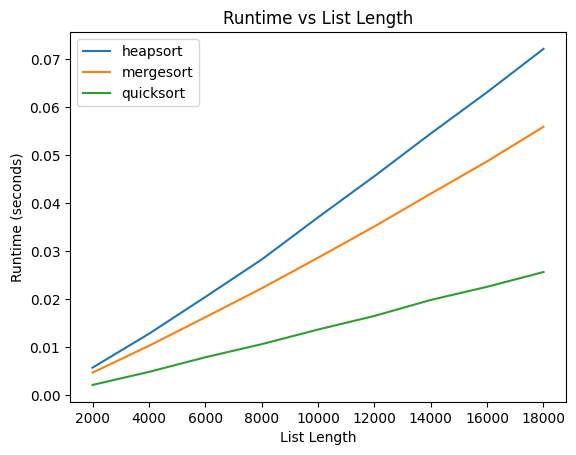

In [ ]:
measure_runtime([heapsort, mergesort, quicksort])
plot_runtime([heapsort, mergesort, quicksort])

**Answer:**

***These algorithms are faster than the ones from the first assignment, as they generally follow an (n log n) pattern instead of (n^2). This is because they do not need to repeatedly go through the whole list for every element.***

***Mergesort and quicksort divide the problem into smaller parts and sort them using recursion, while heapsort organizes the list as a heap and repeatedly moves the biggest element to its correct position.***


---

***It is important to look at the numbers that represent the list length, otherwise it could seem that the previous algorithms work faster. Finally, the difference between these sorting algorithms and their slopes comes from the different operations they perform, which can make them faster or slower even if they have similar time complexity.***

### 5. Runtime Approximations (1 point)

Remark: In this question, we will take Heap Sort as an example, but the results also carry over to Merge Sort or Quick Sort.

Using the statistics from the tests, find a constant `c` such that `f_heap(n) = c * n` is a *linear* (!) function which *approximately* describes the runtime of Heap Sort in *seconds*, depending on the input size `n`.

Implement the function and look at the runtime plot below. You should notice that `f_heap` seems to be a good approximation of the runtime of Heap Sort (usually not much more than 10% error), at least in the displayed range of `n = 2000, ..., 18000`.

Compare to the asymptotic runtime of Heap Sort known from the lecture. How do you explain your observation? Will the approximation still be good with smaller or larger input sizes?

In [ ]:
def f_heap(size):
  return 0 * size

# plot all functions
runtimeDict[f_heap.__name__] = [f_heap(size) for size in sizes]
plot_runtime([heapsort, mergesort, quicksort], [f_heap])

**Answer:**

***Your answer here.***